# Энтропийный анализ активности субталамического ядра при движении у пациентов с болезнью Паркинсона

В работе исследовалось, как меняется регулярность спайковой активности и потенциалов локального поля (LFP) до и после начала движения. Для кривой плотности спайков и широкополосного LFP рассчитывали выборочную (SampEn) и приближённую (ApEn) энтропию. Значения обеих метрик сравнивали с фоновым уровнем отдельно для внешневызванных и самоинициированных движений.

## 1. Данные

Для каждого пациента результаты повторных движений одного типа объединяли по всем его записям. В таблице `ET-all` обозначает объединённые повторы внешневызванных движений, `IG-all` — самоинициированных.

В каждой строке таблицы указано отклонение энтропии от фона для одного пациента, типа движения, сигнала, метрики и временного окна. Время соответствует середине окна и отсчитывается от начала движения, определённого по электромиограмме (ЭМГ).

При расчёте энтропии LFP порог сходства `r` определяли по стандартному отклонению сигнала в текущем окне.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import false_discovery_control, wilcoxon

data_dir = Path("data")
figure_dir = Path("figures")
figure_dir.mkdir(exist_ok=True)
values = pd.read_csv(data_dir / "patient_entropy.csv", float_precision="round_trip")
curve_keys = ["signal", "condition", "metric"]
window_keys = [*curve_keys, "time_s"]

assert not values.duplicated(["participant", *window_keys]).any()
assert np.isfinite(values["entropy_change"]).all()
print(f"Строк: {len(values)}, уникальных идентификаторов: {values['participant'].nunique()}")
values.groupby("condition").agg(пациентов=("participant", "nunique"), окон=("time_s", "nunique"))

Строк: 4480, уникальных идентификаторов: 21


,пациентов,окон
condition,,
ET-all,20,28
IG-all,20,28


## 2. Сравнение энтропии с фоновым уровнем

В каждом временном окне для каждого из 20 пациентов было рассчитано отклонение энтропии от фона. Чтобы проверить, есть ли в группе систематическое повышение или снижение энтропии относительно фона, применялся двусторонний критерий знаковых рангов Уилкоксона. Поправка Бенджамини–Хохберга применялась по 28 временным окнам отдельно для каждого сигнала, типа движения и метрики.

Для каждого окна рассчитывалась медиана отклонения по пациентам. Её 95%-й доверительный интервал оценивался методом бутстрепа: 1000 раз формировалась выборку из 20 пациентов с возвращением и для каждой выборки заново вычислялась медиану.

In [2]:
rows = []
for key, window in values.groupby(window_keys, sort=True):
    changes = window["entropy_change"].to_numpy()
    test = wilcoxon(changes, alternative="two-sided", method="auto")
    rng = np.random.default_rng(42)
    samples = rng.choice(changes, size=(1000, len(changes)), replace=True)
    low, high = np.percentile(np.median(samples, axis=1), [2.5, 97.5])
    rows.append((*key, len(changes), np.median(changes), low, high, test.pvalue))

stats = pd.DataFrame(rows, columns=[
    *window_keys, "n_units", "median_delta", "ci_low", "ci_high", "p_raw"
])
stats["p_fdr"] = stats.groupby(curve_keys)["p_raw"].transform(
    lambda p: false_discovery_control(p, method="bh")
)
stats["reject_fdr"] = stats["p_fdr"] < 0.05
stats.groupby(["signal", "condition", "metric"]).agg(
    пациентов_мин=("n_units", "min"),
    пациентов_макс=("n_units", "max"),
    окон=("time_s", "size"),
    значимых_окон=("reject_fdr", "sum")
)

пациентов_мин  пациентов_макс  окон  значимых_окон
signal condition metric                                                    
LFP    ET-all    apen               20              20    28             11
                 sampen             20              20    28             18
       IG-all    apen               20              20    28              0
                 sampen             20              20    28              0
SPK    ET-all    apen               20              20    28              7
                 sampen             20              20    28             25
       IG-all    apen               20              20    28              0
                 sampen             20              20    28             26

## 3. Кривые энтропии

В каждой панели ноль на горизонтальной оси соответствует началу движения. Горизонтальная пунктирная линия обозначает уровень фона (отклонение равно нулю). Строки соответствуют метрикам, столбцы — типам движения. Звёздочки вверху каждой панели показывают окна, значимые после FDR. Для четырёх панелей одного рисунка используется общая шкала.

In [4]:
def plot_signal(signal, title, filename):
    colors = {"sampen": "#146e78", "apen": "#8a4c37"}
    names = {"sampen": "SampEn", "apen": "ApEn"}
    tasks = {"ET-all": "Внешневызванные (ET)", "IG-all": "Самоинициированные (IG)"}
    fig, axes = plt.subplots(2, 2, figsize=(10.8, 6.6), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.105, right=0.965, top=0.79, bottom=0.175,
                        hspace=0.45, wspace=0.13)
    fig.suptitle(title, y=0.975, fontsize=16, fontweight="bold")
    fig.text(0.5, 0.91, "Линия — медиана по пациентам, заливка — 95%-й бутстреп-интервал",
             ha="center", fontsize=10)
    selected = stats.loc[stats["signal"] == signal]
    low = min(0, selected["ci_low"].min())
    high = max(0, selected["ci_high"].max())
    span = high - low
    for i, (metric, color) in enumerate(colors.items()):
        for j, (condition, label) in enumerate(tasks.items()):
            ax = axes[i, j]
            curve = selected.loc[(selected["metric"] == metric) &
                                 (selected["condition"] == condition)].sort_values("time_s")
            significant = curve.loc[curve["reject_fdr"], "time_s"]
            time = curve["time_s"].to_numpy()
            ax.axvline(0, color="#41494f", linewidth=1)
            ax.axhline(0, color="#72777c", linestyle="--", linewidth=0.8)
            ax.fill_between(time, curve["ci_low"].to_numpy(), curve["ci_high"].to_numpy(),
                            color=color, alpha=0.17, linewidth=0)
            ax.plot(time, curve["median_delta"], color=color, linewidth=2)
            ax.plot(significant, np.full(len(significant), high + 0.12 * span),
                    linestyle="none", marker=(6, 2, 0), markersize=6,
                    markeredgewidth=0.70, markeredgecolor=color, color=color)
            ax.set(xlim=(-2, 4), ylim=(low - 0.06 * span, high + 0.22 * span),
                   xticks=np.arange(-2, 5))
            ax.set_title(f"{names[metric]} · {label}     {len(significant)}/{len(curve)}",
                         loc="left", fontsize=11)
            ax.grid(axis="y", alpha=0.16)
            ax.spines[["right", "top"]].set_visible(False)
    fig.supylabel("Отклонение энтропии от фона", x=0.025, fontsize=11)
    fig.supxlabel("Время относительно начала движения по ЭМГ, с", y=0.085, fontsize=11)
    fig.text(0.5, 0.03, "* — окна с p < 0,05 после FDR. В заголовке — число таких окон из 28.",
             ha="center", fontsize=9)
    fig.savefig(figure_dir / filename, dpi=160)
    return fig

### Спайковая активность

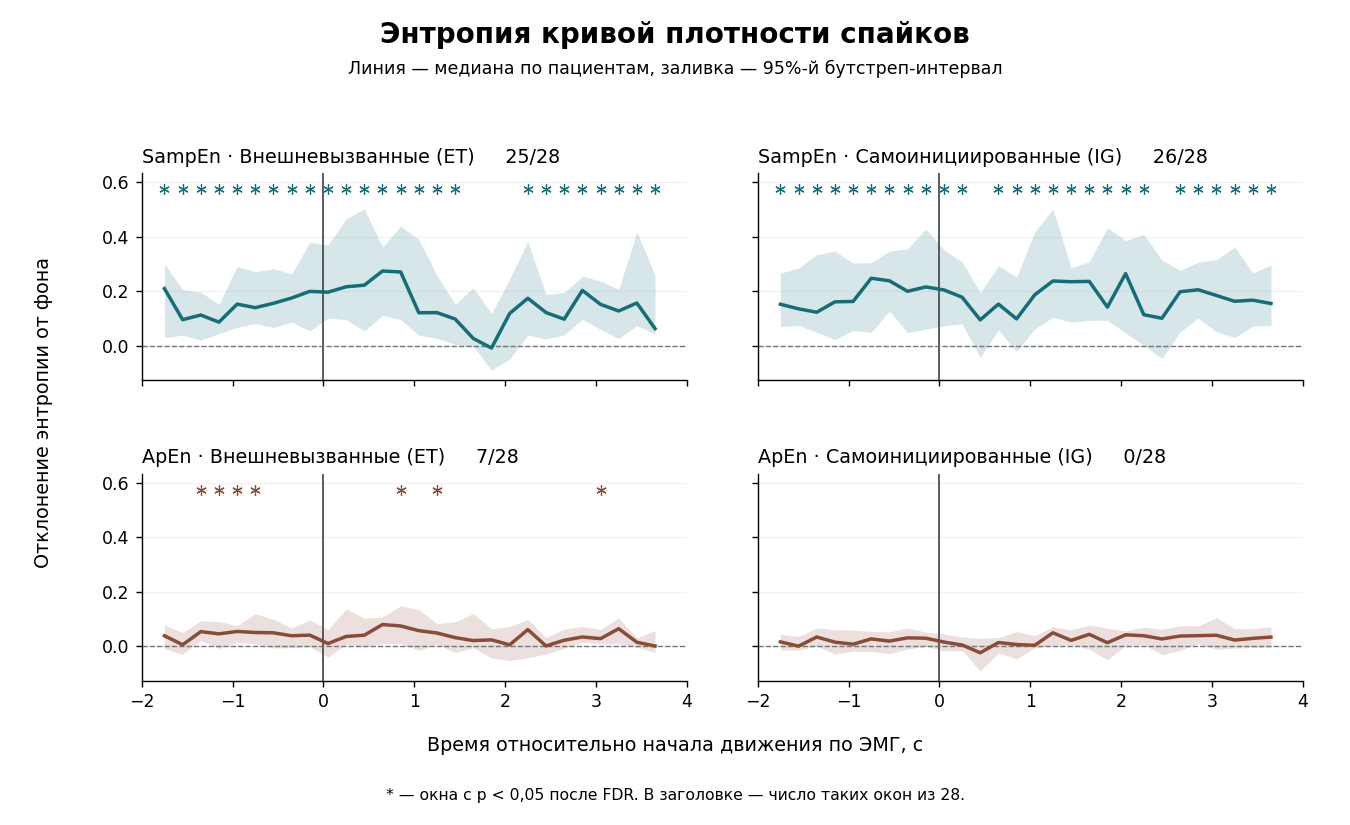

In [5]:
plot_signal("SPK", "Энтропия кривой плотности спайков", "spikes.png")

При внешневызванных движениях значения SampEn были значимо выше фонового уровня в 25 из 28 временных окон, а значения ApEn — в 7 из 28. При самоинициированных движениях значения SampEn были значимо выше фона в 26 из 28 окон. Для ApEn значимых отклонений от фона не обнаружено.

### Широкополосный LFP

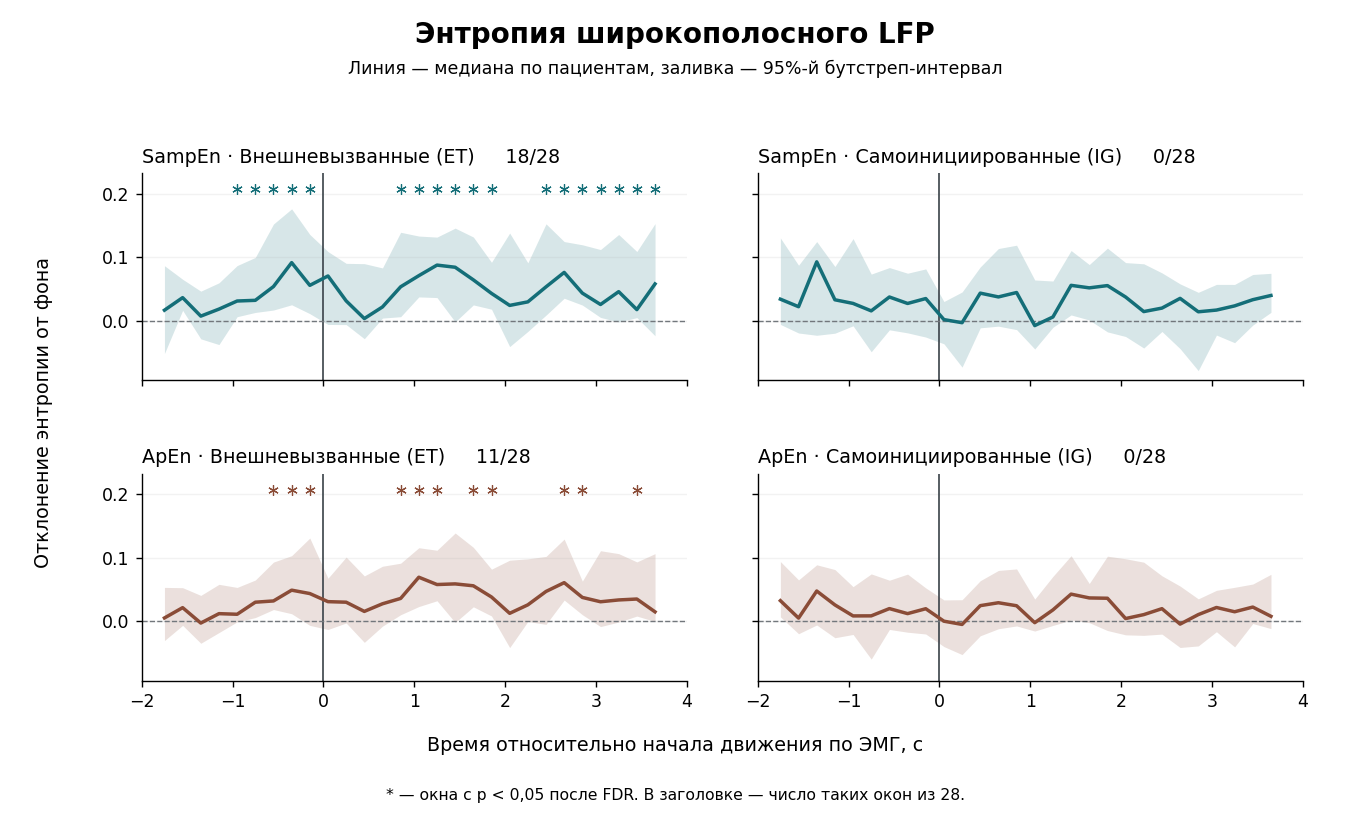

In [6]:
plot_signal("LFP", "Энтропия широкополосного LFP", "lfp.png")

При внешневызванных движениях значения SampEn были значимо выше фонового уровня в 18 из 28 временных окон, а значения ApEn — в 11 из 28. При самоинициированных движениях ни для SampEn, ни для ApEn значимых отклонений от фона не обнаружено.